# Project 16 — AI-Powered Forest Cover Type Classification
**Dataset:** UCI Covertype | **Primary:** Stacking Ensemble | **Comparisons:** Decision Tree, Random Forest, Extra Trees

Run all cells from top to bottom in Google Colab. This notebook downloads the dataset, explores it, creates a common stratified test set, tunes models on training/validation data, trains a leakage-safe stacking ensemble, evaluates all four models, saves results/models/plots, and creates a Streamlit app.

**Leakage safeguards:** The held-out test set is created once and is not used for tuning. `StackingClassifier(cv=3)` trains its Logistic Regression meta-model using out-of-fold base-model predictions. Covertype is not time-dependent, so a stratified random split is used. Tree models do not require scaling. To control Colab runtime, default model development uses at most 100,000 training rows; the test set remains 20% of the full dataset and is shared by all models.

## 1. Install dashboard dependency

In [1]:
%pip -q install streamlit

## 2. Imports, Drive mount and project folders

In [2]:
import os, time, json, joblib, warnings, subprocess, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_covtype
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

try:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/Project_16_Forest_Cover")
except Exception:
    PROJECT_DIR = Path.cwd() / "Project_16_Forest_Cover"

DATA_DIR = PROJECT_DIR / "dataset"
RESULTS_DIR = PROJECT_DIR / "results"
MODELS_DIR = PROJECT_DIR / "models"
APP_DIR = PROJECT_DIR / "app"
NOTEBOOK_DIR = PROJECT_DIR / "notebooks"
for p in [DATA_DIR, RESULTS_DIR, MODELS_DIR, APP_DIR, NOTEBOOK_DIR]:
    p.mkdir(parents=True, exist_ok=True)
print("Project directory:", PROJECT_DIR)

Mounted at /content/drive
Project directory: /content/drive/MyDrive/Project_16_Forest_Cover


## 3. Download and load UCI Covertype

In [3]:
print("Fetching UCI Covertype. The first download may take a few minutes...")
cov = fetch_covtype(download_if_missing=True, as_frame=False)
X = pd.DataFrame(cov.data, columns=cov.feature_names)
y = pd.Series(cov.target, name="Cover_Type").astype(int)

print("Rows:", len(X), "| Features:", X.shape[1], "| Classes:", sorted(y.unique()))
print("Feature matrix:", X.shape, "| Target:", y.shape)
display(X.head())
print("\\nClass counts:")
display(y.value_counts().sort_index().rename("count").to_frame())

Fetching UCI Covertype. The first download may take a few minutes...
Rows: 581012 | Features: 54 | Classes: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7)]
Feature matrix: (581012, 54) | Target: (581012,)


,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type_30,Soil_Type_31,Soil_Type_32,Soil_Type_33,Soil_Type_34,Soil_Type_35,Soil_Type_36,Soil_Type_37,Soil_Type_38,Soil_Type_39
0,2596.0,51.0,3.0,258.0,0.0,510.0,221.0,232.0,148.0,6279.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2590.0,56.0,2.0,212.0,-6.0,390.0,220.0,235.0,151.0,6225.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2804.0,139.0,9.0,268.0,65.0,3180.0,234.0,238.0,135.0,6121.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2785.0,155.0,18.0,242.0,118.0,3090.0,238.0,238.0,122.0,6211.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2595.0,45.0,2.0,153.0,-1.0,391.0,220.0,234.0,150.0,6172.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


\nClass counts:


,count
Cover_Type,
1,211840
2,283301
3,35754
4,2747
5,9493
6,17367
7,20510


## 4. Dataset quality and class distribution

Missing feature values: 0
Duplicate feature rows: 0
Number of classes: 7


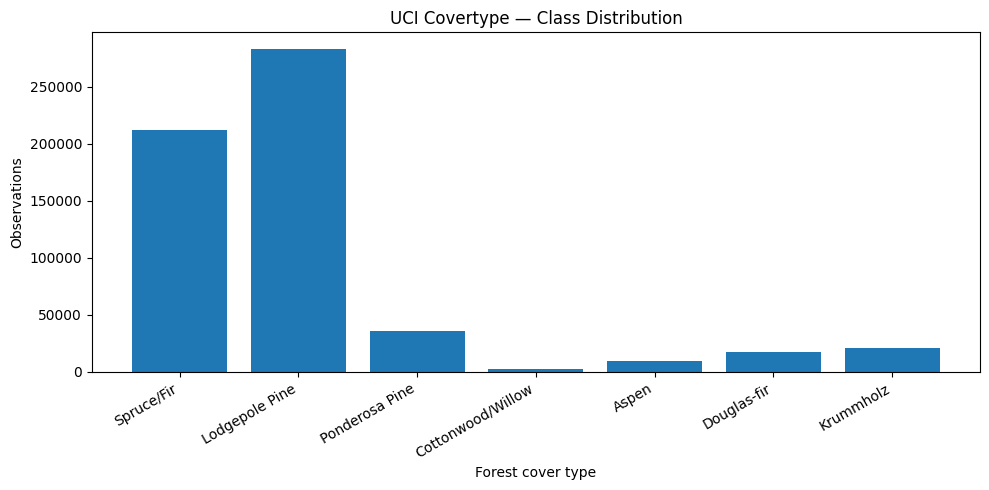

In [4]:
class_names = {
    1:"Spruce/Fir", 2:"Lodgepole Pine", 3:"Ponderosa Pine",
    4:"Cottonwood/Willow", 5:"Aspen", 6:"Douglas-fir", 7:"Krummholz"
}
counts = y.value_counts().sort_index()
print("Missing feature values:", int(X.isna().sum().sum()))
print("Duplicate feature rows:", int(X.duplicated().sum()))
print("Number of classes:", y.nunique())

plt.figure(figsize=(10,5))
plt.bar([class_names[i] for i in counts.index], counts.values)
plt.title("UCI Covertype — Class Distribution")
plt.xlabel("Forest cover type"); plt.ylabel("Observations")
plt.xticks(rotation=30, ha="right"); plt.tight_layout()
plt.savefig(RESULTS_DIR / "01_class_distribution.png", dpi=160)
plt.show()

## 5. Create one common train/validation/test design
First reserve 20% of the complete dataset as the final test set. The test set is not used during tuning. A stratified training sample is used for practical model development. All four final models will be evaluated on exactly the same test rows.

In [5]:
X_train_pool, X_test, y_train_pool, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

TRAIN_SAMPLE_SIZE = 100_000  # Change to None to use the entire training partition.
if TRAIN_SAMPLE_SIZE and len(X_train_pool) > TRAIN_SAMPLE_SIZE:
    X_dev, _, y_dev, _ = train_test_split(
        X_train_pool, y_train_pool, train_size=TRAIN_SAMPLE_SIZE,
        random_state=RANDOM_STATE, stratify=y_train_pool
    )
else:
    X_dev, y_dev = X_train_pool.copy(), y_train_pool.copy()

X_fit, X_val, y_fit, y_val = train_test_split(
    X_dev, y_dev, test_size=0.20, random_state=RANDOM_STATE, stratify=y_dev
)
print("Full dataset:", len(X))
print("Development sample:", len(X_dev), "| fit:", len(X_fit), "| validation:", len(X_val))
print("Common held-out test set:", len(X_test))

Full dataset: 581012
Development sample: 100000 | fit: 80000 | validation: 20000
Common held-out test set: 116203


## 6. Lightweight hyperparameter selection on validation data

In [6]:
candidates = {
 "Decision Tree": [
  DecisionTreeClassifier(max_depth=20, min_samples_leaf=2, class_weight="balanced", random_state=RANDOM_STATE),
  DecisionTreeClassifier(max_depth=None, min_samples_leaf=5, class_weight="balanced", random_state=RANDOM_STATE)
 ],
 "Random Forest": [
  RandomForestClassifier(n_estimators=60, max_features="sqrt", min_samples_leaf=2,
                         class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE),
  RandomForestClassifier(n_estimators=60, max_features=0.7, min_samples_leaf=2,
                         class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE)
 ],
 "Extra Trees": [
  ExtraTreesClassifier(n_estimators=60, max_features="sqrt", min_samples_leaf=2,
                       class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE),
  ExtraTreesClassifier(n_estimators=60, max_features=0.7, min_samples_leaf=2,
                       class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE)
 ]
}

best_estimators, validation_rows = {}, []
for name, options in candidates.items():
    best_f1, best_model = -1, None
    for idx, model in enumerate(options, start=1):
        t0 = time.perf_counter()
        model.fit(X_fit, y_fit)
        fit_seconds = time.perf_counter() - t0
        pred = model.predict(X_val)
        acc = accuracy_score(y_val, pred)
        mf1 = f1_score(y_val, pred, average="macro")
        validation_rows.append({
            "Algorithm":name, "Candidate":idx, "Validation Accuracy":acc,
            "Validation Macro F1":mf1, "Selection Fit Time (s)":fit_seconds
        })
        if mf1 > best_f1:
            best_f1, best_model = mf1, model
    best_estimators[name] = best_model

validation_df = pd.DataFrame(validation_rows)
display(validation_df.sort_values(["Algorithm","Validation Macro F1"], ascending=[True,False]))

,Algorithm,Candidate,Validation Accuracy,Validation Macro F1,Selection Fit Time (s)
0,Decision Tree,1,0.82915,0.752683,1.234098
1,Decision Tree,2,0.83170,0.748149,1.315478
5,Extra Trees,2,0.92855,0.888456,13.526331
4,Extra Trees,1,0.86005,0.785774,4.100372
3,Random Forest,2,0.91950,0.868775,33.270420
2,Random Forest,1,0.89625,0.851770,11.340487


## 7. Configure leakage-safe Stacking Ensemble
The selected Decision Tree, Random Forest and Extra Trees are base learners. With `cv=3`, StackingClassifier generates out-of-fold predictions for the meta-learner. The meta-learner does not train on in-sample predictions from base models.

In [7]:
stack_model = StackingClassifier(
    estimators=[
        ("decision_tree", best_estimators["Decision Tree"]),
        ("random_forest", best_estimators["Random Forest"]),
        ("extra_trees", best_estimators["Extra Trees"])
    ],
    final_estimator=LogisticRegression(max_iter=1000, class_weight="balanced"),
    stack_method="predict_proba",
    cv=3,
    n_jobs=-1,
    passthrough=False
)
print(stack_model)

StackingClassifier(cv=3,
                   estimators=[('decision_tree',
                                DecisionTreeClassifier(class_weight='balanced',
                                                       max_depth=20,
                                                       min_samples_leaf=2,
                                                       random_state=42)),
                               ('random_forest',
                                RandomForestClassifier(class_weight='balanced_subsample',
                                                       max_features=0.7,
                                                       min_samples_leaf=2,
                                                       n_estimators=60,
                                                       n_jobs=-1,
                                                       random_state=42)),
                               ('extra_trees',
                                ExtraTreesClassifier(class_weight='balanced',
    

## 8. Train all final models on the same development rows

In [8]:
final_models = {
    "Decision Tree": best_estimators["Decision Tree"],
    "Random Forest": best_estimators["Random Forest"],
    "Extra Trees": best_estimators["Extra Trees"],
    "Stacking Ensemble": stack_model
}
training_times = {}
for name, model in final_models.items():
    t0 = time.perf_counter()
    model.fit(X_dev, y_dev)
    training_times[name] = time.perf_counter() - t0
    print(f"{name} trained in {training_times[name]:.2f} seconds")

Decision Tree trained in 1.51 seconds
Random Forest trained in 40.98 seconds
Extra Trees trained in 17.01 seconds
Stacking Ensemble trained in 205.55 seconds


## 9. Evaluate all models on the same held-out test set

In [28]:
predictions = {}
rows = []

for name, model in final_models.items():
    t0 = time.perf_counter()
    pred = model.predict(X_test)
    elapsed = time.perf_counter() - t0

    predictions[name] = pred

    # Use the correct validation score for stacking
    if name == "Stacking Ensemble":
        validation_f1 = stack_validation_f1
    else:
        validation_f1 = validation_df.loc[
            validation_df.Algorithm == name,
            "Validation Macro F1"
        ].max()

    rows.append({
        "Algorithm": name,
        "Validation Macro F1": validation_f1,
        "Test Accuracy": accuracy_score(y_test, pred),
        "Test Macro F1": f1_score(
            y_test, pred, average="macro"
        ),
        "Training Time (s)": training_times[name],
        "Inference (ms/row)": elapsed / len(X_test) * 1000,
        "Interpretability": (
            "High" if name == "Decision Tree"
            else "Low" if name == "Stacking Ensemble"
            else "Low–Medium"
        )
    })

results_df = pd.DataFrame(rows).sort_values(
    "Test Macro F1", ascending=False
)

display(results_df.round(4))

results_df.to_csv(
    RESULTS_DIR / "model_comparison.csv",
    index=False
)

print("\nStacking Ensemble classification report:")
print(classification_report(
    y_test,
    predictions["Stacking Ensemble"],
    digits=4
))

,Algorithm,Validation Macro F1,Test Accuracy,Test Macro F1,Training Time (s),Inference (ms/row),Interpretability
2,Extra Trees,0.8885,0.9320,0.8933,17.0128,0.0202,Low–Medium
1,Random Forest,0.8688,0.9230,0.8735,40.9781,0.0334,Low–Medium
3,Stacking Ensemble,0.8489,0.9215,0.8625,205.5512,0.0359,Low
0,Decision Tree,0.7527,0.8287,0.7448,1.5135,0.0014,High



Stacking Ensemble classification report:
              precision    recall  f1-score   support

           1     0.9367    0.9255    0.9311     42368
           2     0.9517    0.9167    0.9339     56661
           3     0.9076    0.9053    0.9065      7151
           4     0.7131    0.9417    0.8116       549
           5     0.5683    0.9415    0.7088      1899
           6     0.7616    0.9107    0.8295      3473
           7     0.8659    0.9725    0.9161      4102

    accuracy                         0.9215    116203
   macro avg     0.8150    0.9306    0.8625    116203
weighted avg     0.9274    0.9215    0.9232    116203



## 10. Confusion matrices for all four models

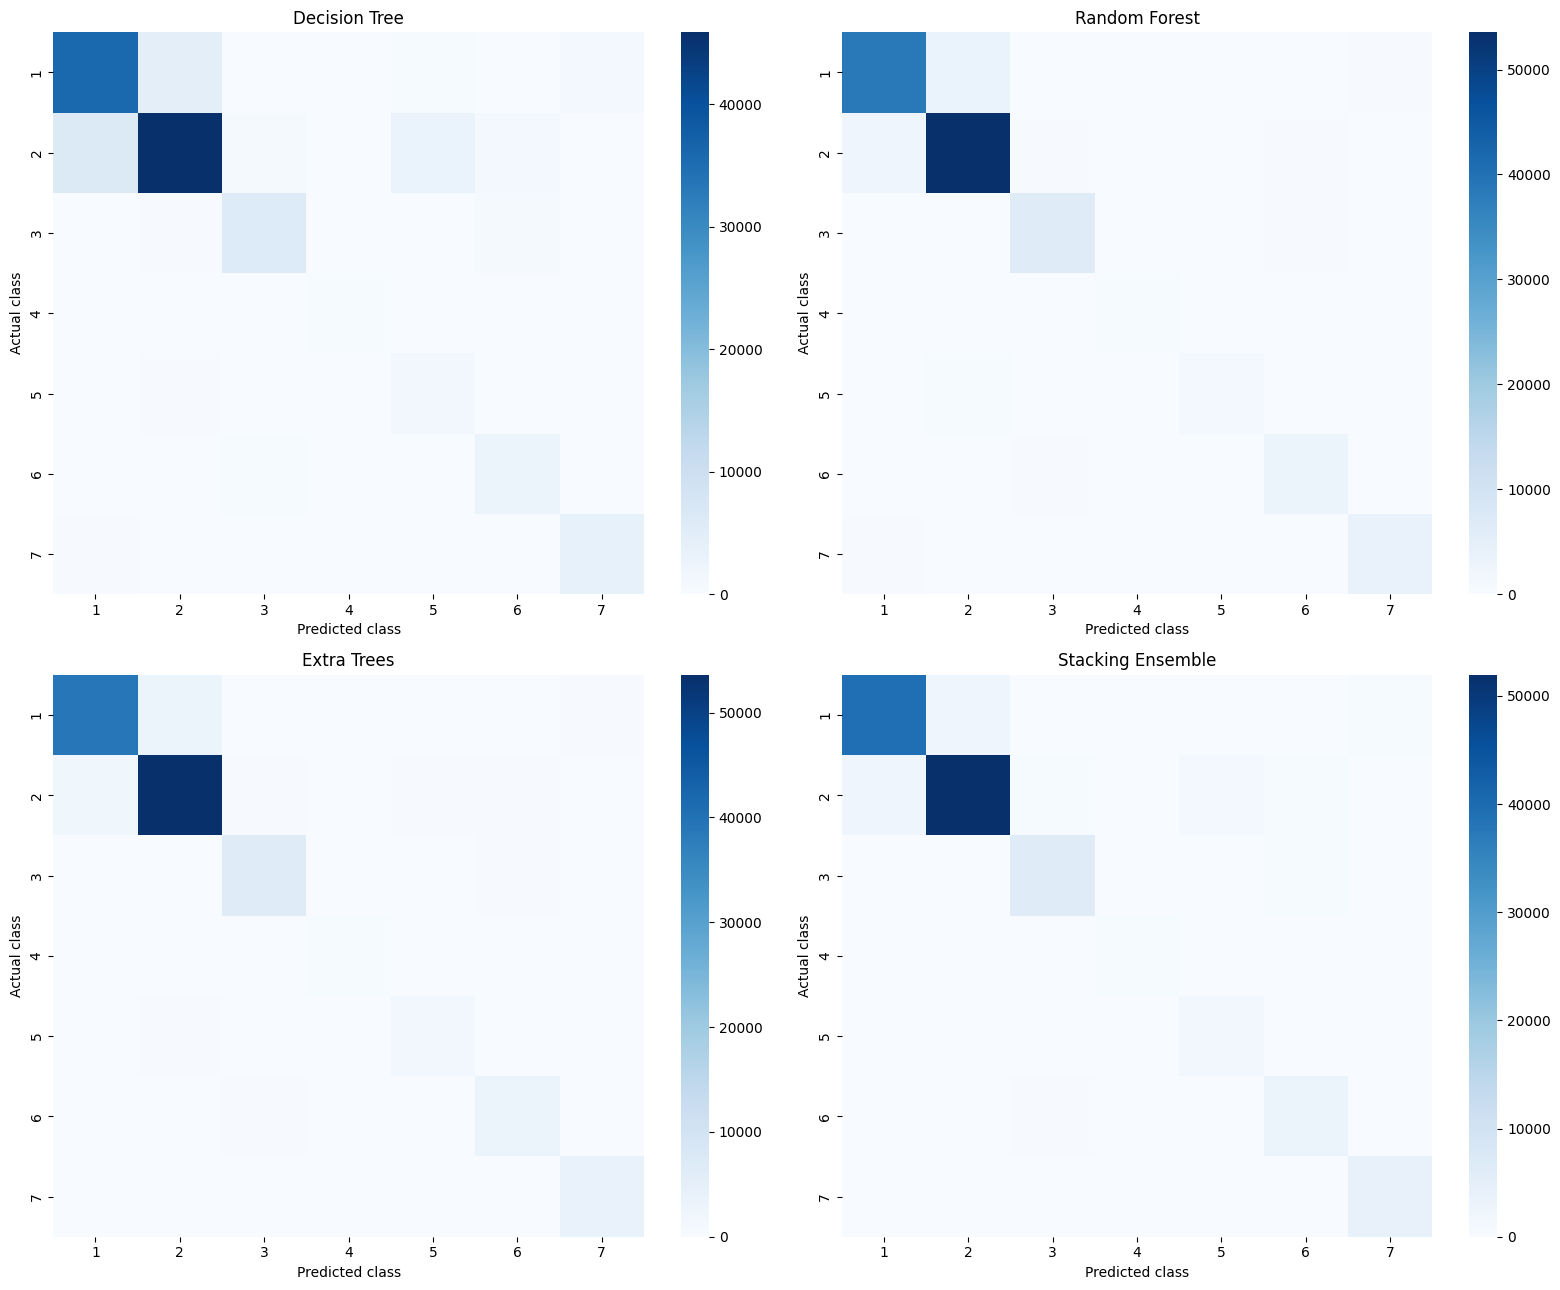

In [10]:
fig, axes = plt.subplots(2,2,figsize=(16,13))
for ax, (name,pred) in zip(axes.ravel(), predictions.items()):
    cm = confusion_matrix(y_test, pred, labels=[1,2,3,4,5,6,7])
    sns.heatmap(cm, cmap="Blues", annot=False, fmt="d", ax=ax,
                xticklabels=[1,2,3,4,5,6,7], yticklabels=[1,2,3,4,5,6,7])
    ax.set_title(name); ax.set_xlabel("Predicted class"); ax.set_ylabel("Actual class")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "02_confusion_matrices.png", dpi=160)
plt.show()

## 11. Compare test accuracy and macro F1

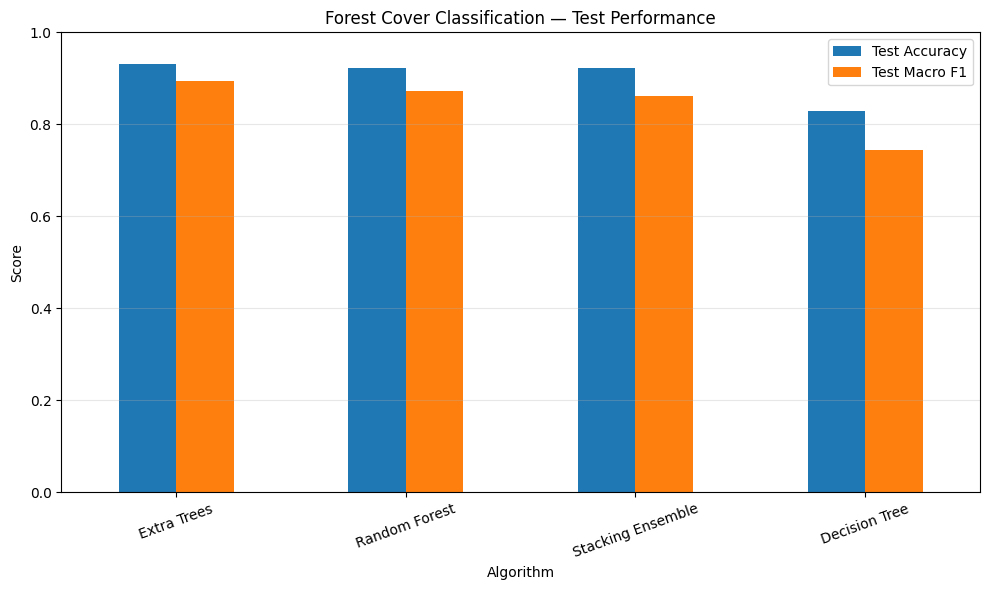

In [11]:
predictions = {}
rows = []
for name, model in final_models.items():
    t0 = time.perf_counter()
    pred = model.predict(X_test)
    elapsed = time.perf_counter() - t0
    predictions[name] = pred
    rows.append({
        "Algorithm":name,
        "Validation Macro F1": (
            validation_df.loc[validation_df.Algorithm == name, "Validation Macro F1"].max()
            if name in validation_df.Algorithm.values else np.nan
        ),
        "Test Accuracy":accuracy_score(y_test, pred),
        "Test Macro F1":f1_score(y_test, pred, average="macro"),
        "Training Time (s)":training_times[name],
        "Inference (ms/row)":elapsed / len(X_test) * 1000,
        "Interpretability": "High" if name == "Decision Tree" else ("Low" if name == "Stacking Ensemble" else "Low–Medium")
    })

results_df = pd.DataFrame(rows).sort_values("Test Macro F1", ascending=False)
display(results_df.round(4))
results_df.to_csv(RESULTS_DIR / "model_comparison.csv", index=False)
print("\\nStacking Ensemble classification report:")
print(classification_report(y_test, predictions["Stacking Ensemble"], digits=4))

## 12. Feature importance (Random Forest)

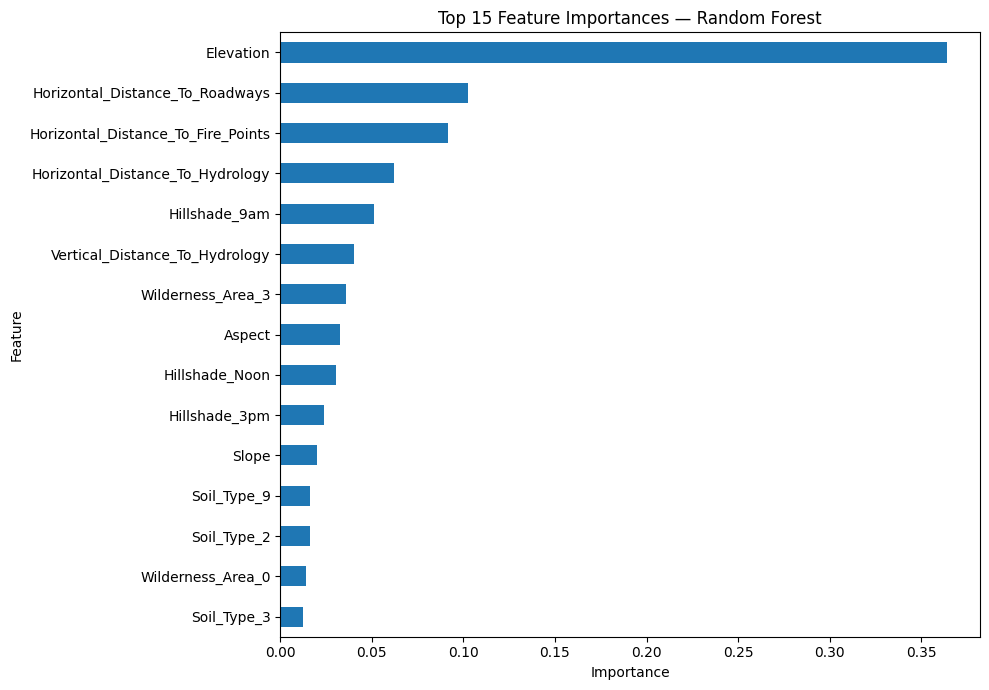

,Importance
Elevation,0.363920
Horizontal_Distance_To_Roadways,0.102727
Horizontal_Distance_To_Fire_Points,0.091654
Horizontal_Distance_To_Hydrology,0.062269
Hillshade_9am,0.051439
Vertical_Distance_To_Hydrology,0.040532
Wilderness_Area_3,0.036128
Aspect,0.032749
Hillshade_Noon,0.030407
Hillshade_3pm,0.023935


In [12]:
importance = pd.Series(
    final_models["Random Forest"].feature_importances_, index=X.columns
).sort_values(ascending=False)
top = importance.head(15).sort_values()
plt.figure(figsize=(10,7))
top.plot(kind="barh")
plt.title("Top 15 Feature Importances — Random Forest")
plt.xlabel("Importance"); plt.ylabel("Feature")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "04_feature_importance.png", dpi=160)
plt.show()
display(importance.head(15).to_frame("Importance"))

## 13. Save models, metadata and example predictions to Drive

In [13]:
for name, model in final_models.items():
    filename = name.lower().replace(" ","_") + ".joblib"
    joblib.dump(model, MODELS_DIR / filename, compress=3)

pd.DataFrame({
    "Actual":y_test.to_numpy(),
    **{name:pred for name,pred in predictions.items()}
}).head(10000).to_csv(RESULTS_DIR / "test_predictions_first_10000.csv", index=False)

metadata = {
    "feature_names":list(X.columns),
    "class_labels":[int(c) for c in sorted(y.unique())],
    "class_names":class_names,
    "training_sample_size":int(len(X_dev)),
    "test_size":int(len(X_test)),
    "random_state":RANDOM_STATE
}
with open(RESULTS_DIR / "model_metadata.json","w") as f:
    json.dump(metadata,f,indent=2)

print("Models saved:", list(MODELS_DIR.iterdir()))
print("Results saved:", list(RESULTS_DIR.iterdir()))

Models saved: [PosixPath('/content/drive/MyDrive/Project_16_Forest_Cover/models/decision_tree.joblib'), PosixPath('/content/drive/MyDrive/Project_16_Forest_Cover/models/random_forest.joblib'), PosixPath('/content/drive/MyDrive/Project_16_Forest_Cover/models/extra_trees.joblib'), PosixPath('/content/drive/MyDrive/Project_16_Forest_Cover/models/stacking_ensemble.joblib')]
Results saved: [PosixPath('/content/drive/MyDrive/Project_16_Forest_Cover/results/01_class_distribution.png'), PosixPath('/content/drive/MyDrive/Project_16_Forest_Cover/results/model_comparison.csv'), PosixPath('/content/drive/MyDrive/Project_16_Forest_Cover/results/02_confusion_matrices.png'), PosixPath('/content/drive/MyDrive/Project_16_Forest_Cover/results/03_model_performance.png'), PosixPath('/content/drive/MyDrive/Project_16_Forest_Cover/results/04_feature_importance.png'), PosixPath('/content/drive/MyDrive/Project_16_Forest_Cover/results/test_predictions_first_10000.csv'), PosixPath('/content/drive/MyDrive/Projec

## 14. Generate Streamlit app source

In [24]:

app_code = r'''
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import streamlit as st

# --------------------------------------------------
# 1. PAGE CONFIGURATION
# --------------------------------------------------
st.set_page_config(
    page_title="Forest Intelligence | AI Classifier",
    page_icon="🌲",
    layout="wide",
    initial_sidebar_state="expanded"
)

# --------------------------------------------------
# 2. LOAD TRAINED MODEL AND METADATA
# --------------------------------------------------
HERE = Path(__file__).resolve().parent
PROJECT = HERE.parent

MODEL_PATH = PROJECT / "models" / "stacking_ensemble.joblib"
META_PATH = PROJECT / "results" / "model_metadata.json"
COMPARISON_PATH = PROJECT / "results" / "model_comparison.csv"

@st.cache_resource
def load_model():
    return joblib.load(MODEL_PATH)

@st.cache_data
def load_metadata():
    with open(META_PATH, "r") as f:
        return json.load(f)

MODEL = load_model()
META = load_metadata()

features = META["feature_names"]
class_names = {
    int(k): v for k, v in META["class_names"].items()
}

# --------------------------------------------------
# 3. PROFESSIONAL STYLING
# --------------------------------------------------
st.markdown("""
<style>
    .stApp {
        background: #101a17;
        color: #edf5ef;
    }

    [data-testid="stSidebar"] {
        background: #172820;
        border-right: 1px solid #294536;
    }

    .main-title {
        font-size: 2.5rem;
        font-weight: 800;
        color: #e9f5ec;
        margin-bottom: 5px;
    }

    .subtitle {
        color: #a8c2b0;
        font-size: 1rem;
        margin-bottom: 25px;
    }

    .section-title {
        font-size: 1.4rem;
        font-weight: 700;
        color: #d9f2df;
        margin-top: 12px;
    }

    .info-card {
        background: linear-gradient(135deg, #1d382b, #244b35);
        border: 1px solid #386448;
        border-radius: 14px;
        padding: 18px;
        margin-bottom: 12px;
    }

    .prediction-card {
        background: linear-gradient(135deg, #174d32, #246b43);
        border: 1px solid #4b9a68;
        border-radius: 16px;
        padding: 25px;
        margin: 15px 0;
    }

    div.stButton > button[kind="primary"] {
        background: #25834c;
        color: white;
        border: none;
        border-radius: 9px;
        font-weight: 700;
        min-height: 45px;
    }

    div.stButton > button[kind="primary"]:hover {
        background: #31a45e;
        color: white;
    }

    div[data-testid="stMetric"] {
        background: #1a2c23;
        border: 1px solid #345340;
        padding: 15px;
        border-radius: 12px;
    }

    h1, h2, h3 {
        color: #e9f5ec;
    }

    .stCaption {
        color: #a8c2b0;
    }
</style>
""", unsafe_allow_html=True)

# --------------------------------------------------
# 4. HEADER
# --------------------------------------------------
st.markdown(
    '<div class="main-title">🌲 Forest Intelligence</div>',
    unsafe_allow_html=True
)
st.markdown(
    '<div class="subtitle">'
    'AI-powered forest cover classification using terrain and soil data.'
    '</div>',
    unsafe_allow_html=True
)

st.markdown("---")

# --------------------------------------------------
# 5. LOAD MODEL COMPARISON RESULTS
# --------------------------------------------------
if COMPARISON_PATH.exists():
    comparison = pd.read_csv(COMPARISON_PATH)
else:
    comparison = pd.DataFrame()

# --------------------------------------------------
# 6. NAVIGATION
# --------------------------------------------------
overview_tab, predict_tab, analytics_tab = st.tabs([
    "📊 Overview",
    "🌳 Forest Prediction",
    "📈 Model Analytics"
])

# --------------------------------------------------
# 7. OVERVIEW
# --------------------------------------------------
with overview_tab:
    st.markdown("## Project Overview")
    st.write(
        "This application predicts forest cover types using "
        "the UCI Covertype dataset and a trained Stacking Ensemble."
    )

    if not comparison.empty:
        best = comparison.sort_values(
            "Test Macro F1", ascending=False
        ).iloc[0]

        best_accuracy = comparison["Test Accuracy"].max()
        best_f1 = comparison["Test Macro F1"].max()

        c1, c2, c3, c4 = st.columns(4)

        c1.metric("Algorithms evaluated", len(comparison))
        c2.metric("Best test accuracy", f"{best_accuracy:.2%}")
        c3.metric("Best test Macro F1", f"{best_f1:.4f}")
        c4.metric("Best model", str(best["Algorithm"]))

    st.markdown("### Dataset information")

    a, b, c = st.columns(3)
    a.metric("Input features", len(features))
    b.metric("Forest cover classes", len(class_names))
    c.metric("Primary algorithm", "Stacking Ensemble")

    st.markdown("### Algorithms in this study")

    st.write(
        "- Decision Tree\n"
        "- Random Forest\n"
        "- Extra Trees\n"
        "- Stacking Ensemble"
    )

    st.info(
        "The displayed performance values are measured results "
        "from the notebook evaluation, not assumed accuracy."
    )

# --------------------------------------------------
# 8. FOREST COVER PREDICTION
# --------------------------------------------------
with predict_tab:
    st.markdown("## Forest Cover Prediction")
    st.write(
        "Enter terrain measurements and select the relevant "
        "wilderness and soil indicators."
    )

    numeric_features = [
        f for f in features
        if not f.startswith("Wilderness_Area")
        and not f.startswith("Soil_Type")
    ]

    wilderness_features = [
        f for f in features if f.startswith("Wilderness_Area")
    ]

    soil_features = [
        f for f in features if f.startswith("Soil_Type")
    ]

    defaults = {
        "Elevation": 2500,
        "Aspect": 180,
        "Slope": 10,
        "Horizontal_Distance_To_Hydrology": 200,
        "Vertical_Distance_To_Hydrology": 30,
        "Horizontal_Distance_To_Roadways": 1000,
        "Hillshade_9am": 220,
        "Hillshade_Noon": 230,
        "Hillshade_3pm": 140,
        "Horizontal_Distance_To_Fire_Points": 1500
    }

    st.markdown("### 1. Terrain measurements")

    input_values = {}

    with st.form("forest_prediction_form"):

        with st.expander("Terrain and environmental measurements",
                         expanded=True):

            cols = st.columns(2)

            for i, feature in enumerate(numeric_features):
                with cols[i % 2]:
                    value = defaults.get(feature, 0)

                    if feature == "Aspect":
                        minimum, maximum = 0.0, 360.0
                    elif feature == "Slope":
                        minimum, maximum = 0.0, 90.0
                    elif feature.startswith("Hillshade"):
                        minimum, maximum = 0.0, 255.0
                    else:
                        minimum, maximum = -1000.0, 10000.0

                    input_values[feature] = st.number_input(
                        feature.replace("_", " "),
                        min_value=minimum,
                        max_value=maximum,
                        value=float(value),
                        step=1.0,
                        help=f"Enter the measured value for {feature}."
                    )

        st.markdown("### 2. Wilderness area")

        with st.expander("Select wilderness area", expanded=False):
            st.caption("Select the applicable area indicator.")
            cols = st.columns(2)

            for i, feature in enumerate(wilderness_features):
                with cols[i % 2]:
                    input_values[feature] = int(
                        st.checkbox(feature.replace("_", " "))
                    )

        st.markdown("### 3. Soil type")

        with st.expander("Select soil type", expanded=False):
            st.caption("Select the applicable soil type indicator.")
            cols = st.columns(3)

            for i, feature in enumerate(soil_features):
                with cols[i % 3]:
                    input_values[feature] = int(
                        st.checkbox(feature.replace("_", " "))
                    )

        submitted = st.form_submit_button(
            "🌲 Predict Forest Cover",
            type="primary",
            use_container_width=True
        )

    if submitted:
        sample = pd.DataFrame(
            [[input_values[f] for f in features]],
            columns=features
        )

        with st.spinner("Analyzing terrain and predicting forest cover..."):
            prediction = int(MODEL.predict(sample)[0])
            predicted_name = class_names.get(
                prediction, "Unknown class"
            )

        st.markdown(
            f"""
            <div class="prediction-card">
                <h3>Predicted Forest Cover</h3>
                <h1>Class {prediction}</h1>
                <h2>{predicted_name}</h2>
                <p>Prediction generated by the Stacking Ensemble model.</p>
            </div>
            """,
            unsafe_allow_html=True
        )

        if hasattr(MODEL, "predict_proba"):
            probabilities = MODEL.predict_proba(sample)[0]

            probability_df = pd.DataFrame({
                "Forest Cover": [
                    f"{int(label)} - "
                    f"{class_names.get(int(label), 'Unknown')}"
                    for label in MODEL.classes_
                ],
                "Probability": probabilities
            }).sort_values("Probability", ascending=False)

            st.markdown("### Class probability distribution")

            chart_df = probability_df.set_index("Forest Cover")
            st.bar_chart(chart_df)

            st.dataframe(
                probability_df.style.format({
                    "Probability": "{:.2%}"
                }),
                use_container_width=True,
                hide_index=True
            )

        prediction_record = sample.copy()
        prediction_record["Predicted_Class"] = prediction
        prediction_record["Predicted_Cover_Type"] = predicted_name

        st.download_button(
            "⬇️ Download prediction",
            data=prediction_record.to_csv(index=False),
            file_name="forest_cover_prediction.csv",
            mime="text/csv"
        )

# --------------------------------------------------
# 9. MODEL ANALYTICS
# --------------------------------------------------
with analytics_tab:
    st.markdown("## Model Performance Analytics")

    if comparison.empty:
        st.warning("Run the notebook evaluation section first.")

    else:
        st.markdown("### Model comparison")

        st.dataframe(
            comparison,
            use_container_width=True,
            hide_index=True
        )

        if "Test Accuracy" in comparison.columns:
            st.markdown("### Test accuracy comparison")

            accuracy_chart = comparison[
                ["Algorithm", "Test Accuracy"]
            ].set_index("Algorithm")

            st.bar_chart(accuracy_chart)

        if "Test Macro F1" in comparison.columns:
            st.markdown("### Test Macro F1 comparison")

            f1_chart = comparison[
                ["Algorithm", "Test Macro F1"]
            ].set_index("Algorithm")

            st.bar_chart(f1_chart)

        st.download_button(
            "⬇️ Download model comparison",
            data=comparison.to_csv(index=False),
            file_name="model_comparison.csv",
            mime="text/csv"
        )

        st.caption(
            "All models should be evaluated on the same held-out test set. "
            "Use measured values in your academic report."
        )

# --------------------------------------------------
# 10. FOOTER
# --------------------------------------------------
st.markdown("---")
st.caption(
    "Forest Intelligence | Academic Machine Learning Project | "
    "UCI Covertype Dataset"
)
'''
(APP_DIR / "app.py").write_text(app_code)
print("Professional dashboard created:", APP_DIR / "app.py")


Professional dashboard created: /content/drive/MyDrive/Project_16_Forest_Cover/app/app.py


## 15. Optional: launch the Streamlit dashboard in Colab
Run after the model and metadata files have been saved. If Colab does not open the forwarded port, the app source remains saved in `app/app.py`.

In [15]:
streamlit_log = open(PROJECT_DIR / "streamlit.log","w")
streamlit_process = subprocess.Popen(
    [sys.executable,"-m","streamlit","run",str(APP_DIR / "app.py"),
     "--server.port","8501","--server.address","0.0.0.0","--server.headless","true"],
    stdout=streamlit_log, stderr=subprocess.STDOUT
)
time.sleep(5)
try:
    from google.colab import output
    output.serve_kernel_port_as_window(8501)
except Exception:
    print("For local execution, open http://localhost:8501")
print("Streamlit process ID:",streamlit_process.pid)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

Streamlit process ID: 3588


## 16. Final summary and reproducibility record
Use the measured results from this cell in the technical report. Do not insert assumed or example accuracy values.

In [16]:
print("PROJECT SUMMARY")
print("Dataset: UCI Covertype")
print("Full rows:",len(X),"| Features:",X.shape[1],"| Classes:",y.nunique())
print("Training sample:",len(X_dev),"| Common test set:",len(X_test))
display(results_df.round(4))
best = results_df.iloc[0]
print(f"Top measured test Macro F1: {best['Algorithm']} = {best['Test Macro F1']:.4f}")
print("\\nSaved output folders:")
for folder in [RESULTS_DIR,MODELS_DIR,APP_DIR]:
    print(folder, ":", len(list(folder.iterdir())), "files")

PROJECT SUMMARY
Dataset: UCI Covertype
Full rows: 581012 | Features: 54 | Classes: 7
Training sample: 100000 | Common test set: 116203


,Algorithm,Validation Macro F1,Test Accuracy,Test Macro F1,Training Time (s),Inference (ms/row),Interpretability
2,Extra Trees,0.8885,0.9320,0.8933,17.0128,0.0120,Low–Medium
1,Random Forest,0.8688,0.9230,0.8735,40.9781,0.0134,Low–Medium
3,Stacking Ensemble,NaN,0.9215,0.8625,205.5512,0.0231,Low
0,Decision Tree,0.7527,0.8287,0.7448,1.5135,0.0006,High


Top measured test Macro F1: Extra Trees = 0.8933
\nSaved output folders:
/content/drive/MyDrive/Project_16_Forest_Cover/results : 7 files
/content/drive/MyDrive/Project_16_Forest_Cover/models : 4 files
/content/drive/MyDrive/Project_16_Forest_Cover/app : 1 files


In [19]:
from google.colab import output
output.serve_kernel_port_as_window(8501)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [20]:
from pathlib import Path

log_path = Path("/content/streamlit.log")

if log_path.exists():
    print(log_path.read_text(errors="ignore")[-5000:])
else:
    print("Streamlit log file not found.")

Streamlit log file not found.


In [21]:
from pathlib import Path

log_path = Path("/content/drive/MyDrive/Project_16_Forest_Cover/streamlit.log")

if log_path.exists():
    print(log_path.read_text(errors="ignore")[-5000:])
else:
    print("Log file not found at project location.")

q8-b.us-west1.prod.r.colab.dev, host=gpu-t4-s-usw1b2-bs5radytgyq8.us-west1-b.c.codatalab-user-runtimes.internal:8007
2026-11-07 08:39:25.812 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-gpu-t4-s-usw1b2-bs5radytgyq8-b.us-west1.prod.r.colab.dev, host=gpu-t4-s-usw1b2-bs5radytgyq8.us-west1-b.c.codatalab-user-runtimes.internal:8007
2026-11-07 08:39:29.883 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-gpu-t4-s-usw1b2-bs5radytgyq8-b.us-west1.prod.r.colab.dev, host=gpu-t4-s-usw1b2-bs5radytgyq8.us-west1-b.c.codatalab-user-runtimes.internal:8007
2026-11-07 08:39:34.584 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-gpu-t4-s-usw1b2-bs5radytgyq8-b.us-west1.prod.r.colab.dev, host=gpu-t4-s-usw1b2-bs5radytgyq8.us-west1-b.c.codatalab-user-runtimes.internal:8007
2026-11-07 08:39:38.795 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://850

In [22]:
import subprocess
import sys
import time
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/Project_16_Forest_Cover")
APP_DIR = PROJECT_DIR / "app"
log_path = PROJECT_DIR / "streamlit.log"

# Stop the previous Streamlit process
if "streamlit_process" in globals():
    if streamlit_process.poll() is None:
        streamlit_process.terminate()
        streamlit_process.wait(timeout=10)

# Restart with Colab-compatible settings
log_file = open(log_path, "w")

streamlit_process = subprocess.Popen(
    [
        sys.executable, "-m", "streamlit", "run",
        str(APP_DIR / "app.py"),
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true",
        "--server.enableCORS", "false",
        "--server.enableXsrfProtection", "false"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT
)

time.sleep(5)

print("Streamlit running:", streamlit_process.poll() is None)

Streamlit running: True


In [23]:
from google.colab import output

output.serve_kernel_port_as_window(8501)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [25]:

import subprocess
import sys
import time
from pathlib import Path

# Stop the previous dashboard process
if "streamlit_process" in globals():
    if streamlit_process.poll() is None:
        streamlit_process.terminate()
        streamlit_process.wait(timeout=10)

# Save dashboard logs
dashboard_log = open(PROJECT_DIR / "streamlit.log", "w")

# Start the updated dashboard
streamlit_process = subprocess.Popen(
    [
        sys.executable, "-m", "streamlit", "run",
        str(APP_DIR / "app.py"),
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true",
        "--server.enableCORS", "false",
        "--server.enableXsrfProtection", "false"
    ],
    stdout=dashboard_log,
    stderr=subprocess.STDOUT
)

time.sleep(5)

print("Dashboard running:", streamlit_process.poll() is None)
print("Updated app:", APP_DIR / "app.py")

from google.colab import output
output.serve_kernel_port_as_window(8501)


Dashboard running: True
Updated app: /content/drive/MyDrive/Project_16_Forest_Cover/app/app.py
Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [26]:
# Evaluate Stacking Ensemble on validation data

stack_validation_predictions = stack_model.predict(X_val)

stack_validation_accuracy = accuracy_score(
    y_val, stack_validation_predictions
)

stack_validation_f1 = f1_score(
    y_val, stack_validation_predictions,
    average="macro"
)

print("STACKING ENSEMBLE VALIDATION RESULTS")
print("------------------------------------")
print(f"Validation Accuracy: {stack_validation_accuracy:.4f}")
print(f"Validation Macro F1: {stack_validation_f1:.4f}")

STACKING ENSEMBLE VALIDATION RESULTS
------------------------------------
Validation Accuracy: 0.9896
Validation Macro F1: 0.9623


In [27]:
# Correct Stacking Ensemble validation evaluation

stack_validation_model = StackingClassifier(
    estimators=[
        ("decision_tree", best_estimators["Decision Tree"]),
        ("random_forest", best_estimators["Random Forest"]),
        ("extra_trees", best_estimators["Extra Trees"])
    ],
    final_estimator=LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),
    stack_method="predict_proba",
    cv=3,
    n_jobs=-1,
    passthrough=False
)

# Train ONLY on training data
stack_validation_model.fit(X_fit, y_fit)

# Evaluate on unseen validation data
stack_validation_predictions = stack_validation_model.predict(X_val)

stack_validation_accuracy = accuracy_score(
    y_val, stack_validation_predictions
)

stack_validation_f1 = f1_score(
    y_val,
    stack_validation_predictions,
    average="macro"
)

print("CORRECT STACKING VALIDATION RESULTS")
print("-----------------------------------")
print(f"Validation Accuracy: {stack_validation_accuracy:.4f}")
print(f"Validation Macro F1: {stack_validation_f1:.4f}")

CORRECT STACKING VALIDATION RESULTS
-----------------------------------
Validation Accuracy: 0.9143
Validation Macro F1: 0.8489


In [29]:
import subprocess
import time

# Stop the old Streamlit process
subprocess.run(["pkill", "-f", "streamlit"], capture_output=True)

time.sleep(2)

# Start Streamlit again with updated CSV data
log_file = open("/content/streamlit.log", "w")

process = subprocess.Popen(
    [
        "streamlit", "run",
        "/content/drive/MyDrive/Project_16_Forest_Cover/app/app.py",
        "--server.port", "8501",
        "--server.enableCORS", "false",
        "--server.enableXsrfProtection", "false"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT
)

time.sleep(5)

print("Streamlit dashboard restarted!")

Streamlit dashboard restarted!


In [30]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Project_16_Forest_Cover"
)

for folder in ["notebooks", "app", "models", "results"]:
    path = PROJECT_DIR / folder
    print(f"\n{folder}/")
    if path.exists():
        for file in path.iterdir():
            print("  ", file.name)
    else:
        print("  Folder not found")


notebooks/

app/
   app.py

models/
   decision_tree.joblib
   random_forest.joblib
   extra_trees.joblib
   stacking_ensemble.joblib

results/
   01_class_distribution.png
   model_comparison.csv
   02_confusion_matrices.png
   03_model_performance.png
   04_feature_importance.png
   test_predictions_first_10000.csv
   model_metadata.json


In [31]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Project_16_Forest_Cover"
)

print("Jupyter notebooks found:")

for file in Path("/content/drive/MyDrive").rglob("*.ipynb"):
    if "Project_16" in file.name or "Forest" in str(file):
        print(file)

Jupyter notebooks found:
/content/drive/MyDrive/Colab Notebooks/Project_16_Forest_Cover_Classification (1).ipynb
/content/drive/MyDrive/Colab Notebooks/Project_16_Forest_Cover_Classification.ipynb
